# CSC_51054_EP - Deep Learning
## Lab 5 - Transformer and Transfer Learning



### 1. Introduction:
<p style="text-align: justify;">
Transfer learning that is, solving tasks with models that have been pretrained on very large amounts of data, was a game changer in many deep learning tasks. In NLP, while annotated data are scarce, raw text is virtually unlimited and readily available. Thus, the ability to learn good representations from plain text could greatly improve general natural language understanding. Learning without labels is enabled via self-supervised learning, a setting in which a system learns to predict part of its input from other parts of its input.

<p>One way to realise this pre-training is to use <i>generative pre-training</i> <a href="https://www.cs.ubc.ca/~amuham01/LING530/papers/radford2018improving.pdf" target='_blank'>[1]</a> of a language model. In this pre-training phase, the model will learn to predict the next tokens in a sequence given the previous ones.</p>
<p>Thus, this phase does not require any type of annotations apart from the input text itself. Once the language model is sufficiently pre-trained, it can be fine-tuned on supervised tasks while requiring minimal changes to its architecture (replacing the classification head).</p>

In this lab we will:
<ul>
    <li>Implement and pretrain a language model with transformer architecture.</li>
    <li>Use the pretrained model (transfer learning) to perform a sentiment analysis task which consists of classifying some books reviews into positive and negative ones.</li>
    <li>Compare the performance of the pretrained model to a model trained from scratch.</li>
</ul>

### 2. The Model:
<p style="text-align: justify;">

Our model is based on Transformers<a href="https://arxiv.org/abs/1706.03762" target='_blank'>[2]</a>. While the Transformer is a model that follows the encoder-decoder structure, it is possible to use only the encoder part (as in BERT) or the decoder part (as in gpt) to perform some specific tasks. In this notebook, we use a multi-layer Transformer decoder for the language model. Fortunatly, PyTorch recent releases include a standard transformer blocks that can be easily used and adapted.

Let's start by implementing the model. The different layers used in this model are the following:

- The embedding layer
- Positional Embedding
- The transformer layers
- Linear layer for decoding and classification

<img src='https://1drv.ms/i/c/ae69638675180117/UQQXARh1hmNpIICuGGIEAAAAAP8J49Pyubo4ezI?width=815&height=680'  alt="Drawing" width= '500px'/>


The same model can be used for language modeling and classification by just replacing the last layer in the model. This is why we split our model into two modules:

- base module: which consists of the 3 first layers.
- classifier module: which consists of the last layer.

After the pretraining, the parameters of the base model can be "transferred" to the model used in the classfication task, while the classifier module should be replaced by a new head initialized randomly.

Some of the code is adapted from this nice tutorial: <a href="https://pytorch.org/tutorials/beginner/transformer_tutorial.html" target="_blank">https://pytorch.org/tutorials/beginner/transformer_tutorial.html</a>



In [1]:
import math

import numpy as np
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

> **Task 1**: Fill in the gaps in the `TransformerModel()` class to implement the described model.

### The Model

In [2]:
class PositionalEncoding(nn.Module):
    def __init__(self, nhid, dropout=0.1, max_len=5000):
        super(PositionalEncoding, self).__init__()
        self.dropout = nn.Dropout(p=dropout)

        pe = torch.zeros(max_len, nhid)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, nhid, 2).float() * (-math.log(10000.0) / nhid)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0).transpose(0, 1)
        self.register_buffer("pe", pe)

    def forward(self, x):
        x = x + self.pe[: x.size(0), :]
        return self.dropout(x)

In [3]:
class TransformerModel(nn.Module):
    def __init__(self, ntoken, nhead, nhid, nlayers, dropout=0.5):
        super(TransformerModel, self).__init__()
        '''
        ntokens: the size of vocabulary
        nhid: the hidden dimension of the model.
        We assume that embedding_dim = nhid
        nlayers: the number of nn.TransformerEncoderLayer in nn.TransformerEncoder
        nhead: the number of heads in the multiheadattention models
        dropout: the dropout value
         '''
        self.model_type = "Transformer"
        self.encoder = nn.Embedding(ntoken, nhid) # fill me, nhid = the dim_embed
        self.pos_encoder = PositionalEncoding(nhid, dropout) #fill me, the PositionalEncoding class is implemented in the next cell
        encoder_layers = nn.TransformerEncoderLayer(nhid, nhead, nhid, dropout) #fill me we assume nhid = d_model = dim_feedforward
        self.transformer_encoder = nn.TransformerEncoder(encoder_layers, nlayers) #fill me
        self.nhid = nhid
        self.init_weights()

    def generate_square_subsequent_mask(self, sz):
        mask = (torch.triu(torch.ones(sz, sz)) == 1).transpose(0, 1)
        mask = (
            mask.float()
            .masked_fill(mask == 0, float("-inf"))
            .masked_fill(mask == 1, float(0.0))
        )
        return mask

    def init_weights(self):
        initrange = 0.1
        self.encoder.weight.data.uniform_(-initrange, initrange)

    def forward(self, src, src_mask):
        src = self.encoder(src) * math.sqrt(self.nhid)
        src = self.pos_encoder(src)
        output = self.transformer_encoder(src, src_mask) #fill me
        return output


class ClassificationHead(nn.Module):
    def __init__(self, nhid, nclasses):
        super(ClassificationHead, self).__init__()
        self.decoder = nn.Linear(nhid, nclasses)
        self.init_weights()

    def init_weights(self):
        initrange = 0.1
        self.decoder.bias.data.zero_()
        self.decoder.weight.data.uniform_(-initrange, initrange)

    def forward(self, src):
        output = self.decoder(src) #fill me
        return output

class Model(nn.Module):
    def __init__(self, ntoken, nhead, nhid, nlayers, nclasses, dropout=0.5):
        super(Model, self).__init__()
        self.base = TransformerModel(ntoken, nhead, nhid, nlayers, dropout)
        self.classifier = ClassificationHead(nhid, nclasses)

    def forward(self, src, src_mask):
        # base model
        x = self.base(src, src_mask) #fill me
        # classifier model
        output = self.classifier(x) # fill me
        return output

Let's verify if our model works, by applying one inference step

In [4]:
ntokens = 100 #fill me # the size of vocabulary
nhid = 200  # hidden dimension
nlayers = 4  # the number of nn.TransformerEncoderLayer in nn.TransformerEncoder
nhead = 2  # the number of heads in the multiheadattention models
dropout = 0  # the dropout value

model = Model(ntokens, nhead, nhid, nlayers, ntokens, dropout).to(device)
dummy_input = torch.tensor([[2, 6, 2, 5, 43, 21]]).to(device)
src_mask = model.base.generate_square_subsequent_mask(1).to(device)
out = model.forward(dummy_input, src_mask)

print(out.shape) # is it the right shape?

torch.Size([1, 6, 100])


/Users/jeremie/miniconda3_arm/envs/inf554/lib/python3.12/site-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


## 3.Vocabulary and Tokenization

To train the language model, the text in our corpus should be first tokenized. We use sentencepiece <a href="https://github.com/google/sentencepiece">https://github.com/google/sentencepiece</a> that implements byte-pair-encoding (BPE), a sub-word tokenization algorithm.<br>
The vocabulay is given in `dict.txt` file. Let's load it, and map each token to a unique index.<br>

In our experiments we use datasets that are already tokenized.


> **Task 2**: Fill in the gaps to create a `token2ind` and `ind2token` mapping dictionaries

In [23]:
!wget -nc https://raw.githubusercontent.com/moussaKam/transfer_learning_transformers/main/dict.txt
!head -5 dict.txt

Fichier « dict.txt » déjà présent ; pas de récupération.

▁d 1
es 1
▁l 1
en 1
on 1


In [6]:
path_vocab = "dict.txt"
token2ind = {"<sos>": 0, "<pad>": 1, "<eos>": 2, "<oov>": 3} # the 4 first indices are reserved to special tokens
with open(path_vocab, "r") as f:
    for idx, line in enumerate(f):
        word = line.split()[0].strip()
        token2ind[word] = idx + 4  #fill me

ind2token = {value: key for key, value in token2ind.items()} #fill me

print(ind2token[1111])

▁trop


## 4.Data Loader
We use the `DataLoader` class, to load our dataset and generate the mini-batches used in the training. `get_loader()` returns a `DataLoader`  object, which is an iterable over data samples. The data loader can return mini-batches for language modeling or sequence classification based on the `task` argument that we pass to `get_loader()` function. Currently the function supports <i>language_modeling</i> and <i>classification</i> tasks.<br>

For the <i>language_modeling</i> task, both the input and the target are batches of sequences. In fact, the target is basically a shifted version of
the input, in such a way that each token is predicted given all previous tokens. For example, for a sequence A B C D: <br>
<b>Input:</b>`\<sos\>`A B C D<br>
<b>Output:</b>A B C D`\<eos\>`<br>

For the <i>classification</i> task,
the input is a batch of sequences and
the target is a batch of scalar labels.<br>
For more information about data loaders check: <a href="https://pytorch.org/docs/stable/data.html">https://pytorch.org/docs/stable/data.html</a>


> **Task 3**: Fill in the gap inside `Dataset` class in order to create the input sequence

In [7]:
class Dataset(Dataset):
    def __init__(
        self,
        path_documents,
        path_labels=None,
        token2ind={},
        max_len=512,
        task="language_modeling",
    ):
        self.task = task
        self.max_len = max_len
        self.token2ind = token2ind
        self.documents = []
        self.labels = []
        with open(path_documents, "r") as f1:
            for line in f1:
                self.documents.append(line.strip())
        if task == "classification": # fill me
            with open(path_labels, "r") as f1:
                for line in f1:
                    self.labels.append(int(line.strip()))
            assert len(self.labels) == len(self.documents)

    def __len__(self):
        return len(self.documents)

    def __getitem__(self, index):
        sequence = self.documents[index].split()
        if len(sequence) > self.max_len - 1:
            sequence = sequence[: self.max_len - 1]
        source_sequence = [self.token2ind["<sos>"]] + [
            self.token2ind[word] if word in self.token2ind else self.token2ind["<oov>"]
            for word in sequence[: self.max_len]
        ]
        if self.task == "language_modeling":
            target = source_sequence[1:]
            target.append(self.token2ind["<eos>"])
        elif self.task == "classification":
            target = [self.labels[index]]
        sample = {
            "source_sequence": torch.tensor(source_sequence),
            "target": torch.tensor(target),
        }
        return sample


def MyCollator(batch):
    source_sequences = pad_sequence(
        #we use padding to match the length of the sequences in the same batch
        [sample["source_sequence"] for sample in batch], padding_value=token2ind["<pad>"]
    )
    target = pad_sequence(
        [sample["target"] for sample in batch], padding_value=token2ind["<pad>"]
    )
    return source_sequences, target.reshape(-1)


def get_loader(
    path_documents,
    path_labels=None,
    token2ind={},
    max_len=512,
    batch_size=32,
    task="language_modeling",
):
    dataset = Dataset(
        path_documents,
        path_labels=path_labels,
        token2ind=token2ind,
        max_len=512,
        task=task,
    )
    data_loader = DataLoader(
        dataset=dataset,
        batch_size=batch_size,
        shuffle=True,
        collate_fn=MyCollator,
        pin_memory=False,
        drop_last=True,
    )
    return data_loader

In [8]:
ntokens = len(ind2token) #fill me # the size of vocabulary
nhid = 200  # the dimension of the feedforward network model in nn.TransformerEncoder
nlayers = 4  # the number of nn.TransformerEncoderLayer in nn.TransformerEncoder
nhead = 2  # the number of heads in the multiheadattention models
dropout = 0  # the dropout value

nclasses = 2 # for classification task only

model = Model(ntokens, nhead, nhid, nlayers, ntokens, dropout).to(device)

In [9]:
# optimization paramerters
criterion = nn.CrossEntropyLoss(ignore_index=token2ind['<pad>'])
lr = 0.0003  # learning rate
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

In [24]:
!wget -nc https://raw.githubusercontent.com/moussaKam/transfer_learning_transformers/main/pretraining_subset.txt
path_data_train = "pretraining_subset.txt"

Fichier « pretraining_subset.txt » déjà présent ; pas de récupération.



## 5.The Training
In this section we will implement a `train()` function that trains our model for one epoch. As we said, in this lab we will use a language modeling objective in
the pretraining phase. Given the previous tokens in a sequence,
the model will try to predict
the next one. The same function can be used for both pretraining and fine-tuning phase.<br>

The training procedure is as follows:<br>
1. Iterate over the data-loader.<br>
2. In each iteration perform one forward pass.<br>
3. Compute
the loss through back-propagation.<br>
4. update
the parameters of your model using sgd.<br>
5. repeat for <i>n</i> epochs<br>

<b>N.B:</b>  While in
the <i>language_modeling</i> task all
the vectors at
the output of
the base model are used, in
the <i>classification</i> task we only use
the vector representing
the last token to perform
the prediction.<br>

> **Task 4**: Fill in the gaps in `train()` function.


In [11]:
def train(
    path_data_train: str,
    path_labels_train=None,
    log_interval=5,
    task="language_modeling",
    batch_size=32,
    max_step: int = None,
    current_epoch = None,
):
    model.train()
    total_loss = 0.0
    ntokens = len(token2ind)
    data_loader = get_loader(
        path_data_train,
        path_labels_train,
        token2ind,
        task=task,
        batch_size=batch_size,
    )

    losses = []
    for idx, data in enumerate(data_loader): #1
        optimizer.zero_grad()
        src_mask = model.base.generate_square_subsequent_mask(data[0].size(0)).to(
            device
        )
        input = data[0].to(device)
        output = model(input, src_mask) #2
        if task == 'classification':
            output = output[-1, :]
        output = output.view(-1, output.shape[-1])
        target = data[1] #fill me
        target = target.to(device)
        loss = criterion(output, target) #fill me, Cross entropy check next cells
        loss.backward() #3
        torch.nn.utils.clip_grad_norm_(model.parameters(), 0.5) # prevent exploding gradient
        optimizer.step() #4
        total_loss += loss.item() # fill me
        if (idx % log_interval == 0 and idx > 0) or (max_step is not None and idx == max_step):
            cur_loss = total_loss / log_interval
            print(
                "| epoch {:3d} | {:5d}/{:5d} steps | "
                "loss {:5.5f} | ppl {:8.3f}".format(
                    current_epoch, idx, len(data_loader), cur_loss, math.exp(cur_loss),
                )
            )
            losses.append(cur_loss)
            total_loss = 0

        if max_step is not None and idx >= max_step:
            break

    return losses

In [12]:
#pretraining on a tiny subset
log_interval = 50
epochs = 1
for epoch in range(1, epochs + 1): #5
    train(
        path_data_train,
        task="language_modeling",
        batch_size=16,
        log_interval=log_interval,
        max_step=500,
        current_epoch=epoch,
    )

| epoch   1 |    50/ 3125 steps | loss 9.52434 | ppl 13688.879
| epoch   1 |   100/ 3125 steps | loss 7.63966 | ppl 2079.043
| epoch   1 |   150/ 3125 steps | loss 7.32726 | ppl 1521.207
| epoch   1 |   200/ 3125 steps | loss 7.24797 | ppl 1405.243
| epoch   1 |   250/ 3125 steps | loss 7.11503 | ppl 1230.316
| epoch   1 |   300/ 3125 steps | loss 6.97779 | ppl 1072.544
| epoch   1 |   350/ 3125 steps | loss 6.90271 | ppl  994.962
| epoch   1 |   400/ 3125 steps | loss 6.79481 | ppl  893.200
| epoch   1 |   450/ 3125 steps | loss 6.76342 | ppl  865.593
| epoch   1 |   500/ 3125 steps | loss 6.80832 | ppl  905.348


## 6. Text Generation
Being trained on a language modeling objective, our model can be used in the inference mode to generate/complete sentences. However, the pretraining phase takes a lot of time compared to the fine-tuning.

Of course, we don't have enough time and resources to efficiently pretrain our model, so instead we will load the weights from a checkpoint that has been pre-trained for 12 hours on 1 GPU.<br>

Take a look here: <a href="https://pytorch.org/tutorials/beginner/saving_loading_models.html#saving-loading-a-general-checkpoint-for-inference-and-or-resuming-training">https://pytorch.org/tutorials/beginner/saving_loading_models.html#saving-loading-a-general-checkpoint-for-inference-and-or-resuming-training</a><br>


> **Task 5** Implement the function `infer_next_tokens()` that takes as input a string `sent` and an integer `max_len` and returns a completion of the input sentence. The generation should stop when the model generates `&lt;eos&gt;` or the length of the generated sentence reaches `max_len`


In [25]:
!wget -nc https://raw.githubusercontent.com/moussaKam/transfer_learning_transformers/main/pretrained_model_4layers.pt

model = Model(ntokens, nhead, nhid, nlayers, ntokens).to(device)

#load the checkpoint
checkpoint = torch.load('pretrained_model_4layers.pt', map_location=device)
#load state dict
model.load_state_dict(checkpoint['model_state_dict'])

Fichier « pretrained_model_4layers.pt » déjà présent ; pas de récupération.



/Users/jeremie/miniconda3_arm/envs/inf554/lib/python3.12/site-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


<All keys matched successfully>

In [26]:
!wget -nc https://raw.githubusercontent.com/moussaKam/transfer_learning_transformers/main/sentencepiece.french.model

import sentencepiece as spm

s = spm.SentencePieceProcessor(model_file='sentencepiece.french.model') #load sentencepiece model

#examples
encoded = s.encode_as_pieces("Bonjour les amis!")
decoded = s.decode_pieces(encoded)
print(encoded)
print(decoded)

Fichier « sentencepiece.french.model » déjà présent ; pas de récupération.

['▁Bonjour', '▁les', '▁amis', '!']
Bonjour les amis!


In [15]:
def infer_next_token(sent):
    model.eval()
    sent_pieces = s.encode_as_pieces(sent)
    source = [token2ind['<sos>']] + [token2ind[el] for el in sent_pieces]
    source = torch.tensor(source).to(device)
    source = source.reshape(-1, 1)
    src_mask = model.base.generate_square_subsequent_mask(source.size(0)).to(device)
    out = model(source, src_mask)
    next_token_ind = out[-1].argmax(-1)
    return next_token_ind, out

def infer_next_tokens(sent, max_len=50) -> str:
    sent_pieces = sent.split()
    while True: #greedy
        token_ind, out = infer_next_token(' '.join(sent_pieces)) #fill me
        token = ind2token[token_ind.item()]
        if token == '<eos>': # fill me
            return " ".join(sent_pieces)
        sent_pieces.append(s.decode_pieces([token]))
        if len(sent_pieces) >= max_len:
            return " ".join(sent_pieces)

In [16]:
sent = "Bonjour les"
infer_next_tokens(sent)

'Bonjour les gens qui ont été très accueillants et sympathiques .'

## 7. Supervised task
It's time to train the model on the supervised task, which is in our case sentiment analysis. It consists of predicting whether a book review is a positive or a negative review. The model will be trained in 2 settings.<br>
<ul>
    <li>Training from scratch: All model parameters are randomly initialized.</li>
    <li>Transfer learning: Only the classification head is trained from scratch, all other parameters are copied from the pre-trained model.</li>
</ul>

The training function is already implemented. However, to evaluate the model at each epoch we have to implement a function that computes the accuracy of the model on the validation set.<br>



In [27]:
!wget -nc https://raw.githubusercontent.com/moussaKam/transfer_learning_transformers/main/cls-books/train.review.spm
!wget -nc https://raw.githubusercontent.com/moussaKam/transfer_learning_transformers/main/cls-books/train.label
!wget -nc https://raw.githubusercontent.com/moussaKam/transfer_learning_transformers/main/cls-books/test.review.spm
!wget -nc https://raw.githubusercontent.com/moussaKam/transfer_learning_transformers/main/cls-books/test.label

path_data_train = "train.review.spm"
path_labels_train = "train.label"

path_data_valid = "test.review.spm"
path_labels_valid = "test.label"

Fichier « train.review.spm » déjà présent ; pas de récupération.

Fichier « train.label » déjà présent ; pas de récupération.

Fichier « test.review.spm » déjà présent ; pas de récupération.

Fichier « test.label » déjà présent ; pas de récupération.



> **Task 6:** Implement the <code>accuracy()</code> function. This function takes as input a <code>data_loader</code> and returns an float.<br>

In [18]:
# a function to evaluate the validation accuracy of the model.
def evaluate_accuracy(data_loader):
    model.eval()
    total_loss = 0.0
    ntokens = len(token2ind)
    ncorrect = ntotal = 0
    with torch.no_grad():
        for idx, data in enumerate(data_loader):
            src_mask = model.base.generate_square_subsequent_mask(
                data[0].size(0)
            ).to(device)
            # inference
            output = model(data[0].to(device), src_mask) #fill me
            output = output[-1, :] # only last vector
            # total number of examples
            ntotal += output.shape[0] #fill me
            # number of correct predictions
            predictions = torch.argmax(output, -1)
            ncorrect += torch.sum(predictions == data[1].to(device)) #fill me
        acc = ncorrect.item() / ntotal
        print("validation accuracy: {}".format(acc))
        return acc

In [19]:
#save the base model to be loaded later in the fine-tuning phase
torch.save({"model_state_dict": model.base.state_dict(),}, "pretrained_model_4layers_no_class_head.pt")

In [20]:
from_scratch_settings = [True, False]

from_scratch_valid_acc = []
pretrained_valid_acc = []
lr = 0.0001

for from_scratch in from_scratch_settings:
    model = Model(ntokens, nhead, nhid, nlayers, 2, dropout).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    if not from_scratch:
        print("=====PRETRAINED MODEL======")
        #load checkpoint
        checkpoint = torch.load("pretrained_model_4layers_no_class_head.pt")
        #load state dict
        model.base.load_state_dict(checkpoint['model_state_dict'])
    else:
        print("=====Trainig FROM SCRATCH======")
    epochs = 15
    for epoch in range(1, epochs + 1):
        train(
            path_data_train,
            path_labels_train,
            task='classification',
            batch_size=8,
            log_interval=50,
            current_epoch=epoch,
        )
        acc = evaluate_accuracy(
            get_loader(
                path_data_valid,
                path_labels_valid,
                token2ind=token2ind,
                batch_size=20,
                task='classification',
            )
        )
        if from_scratch:
            from_scratch_valid_acc.append(acc)
        else:
            pretrained_valid_acc.append(acc)
    print()

=====Trainig FROM SCRATCH======
| epoch   1 |    50/  200 steps | loss 0.75512 | ppl    2.128
| epoch   1 |   100/  200 steps | loss 0.74334 | ppl    2.103
| epoch   1 |   150/  200 steps | loss 0.71551 | ppl    2.045
validation accuracy: 0.572
| epoch   2 |    50/  200 steps | loss 0.63674 | ppl    1.890
| epoch   2 |   100/  200 steps | loss 0.57810 | ppl    1.783
| epoch   2 |   150/  200 steps | loss 0.65850 | ppl    1.932
validation accuracy: 0.6185
| epoch   3 |    50/  200 steps | loss 0.44864 | ppl    1.566
| epoch   3 |   100/  200 steps | loss 0.33706 | ppl    1.401
| epoch   3 |   150/  200 steps | loss 0.30068 | ppl    1.351
validation accuracy: 0.7605
| epoch   4 |    50/  200 steps | loss 0.14444 | ppl    1.155
| epoch   4 |   100/  200 steps | loss 0.13799 | ppl    1.148
| epoch   4 |   150/  200 steps | loss 0.22905 | ppl    1.257
validation accuracy: 0.7355
| epoch   5 |    50/  200 steps | loss 0.03800 | ppl    1.039
| epoch   5 |   100/  200 steps | loss 0.01802 | pp

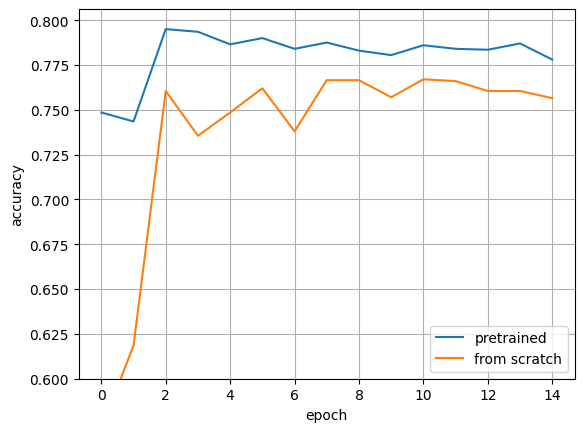

In [21]:
plt.grid()
plt.plot(pretrained_valid_acc, label='pretrained') #fill me
plt.plot(from_scratch_valid_acc, label='from scratch') #fill me
plt.ylim(.6)
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend()